# Preparacion de los datos

In [35]:
from src.data import dataset
import pandas as pd
import importlib
from pathlib import Path

from src.data import preprocesing as prp
importlib.reload(prp)

importlib.reload(dataset)
import torch

## 1. Extracción de los datos y generación de `selected_images.csv`

Usando las funciones de [`dataset.py`](../src/data/dataset.py):
- `extractData()`: elegimos el número de imágenes que queremos por clase. Al ser 10 clases, tendremos un total de 300 imágenes totales cogidas de manera aleatoria. Para su trazabilidad, se usa una semilla (`42`). 

- `get_image()`: se recogen las imagenes extraidas de la anterior función para poder, posteriormente crear un `dataframe` de pandas con:
```json
{
"image_id": row["image_id"],
"path": row["path"],
"true_label": row["true_label"],
"image": image
}
```
- `createFil_selectedImages()`: genera el propio fichero `.csv` en la carpeta de `metadata`.

In [ ]:
df = dataset.extractData(number_class=30)
dataset.createFil_selectedImages(df)

,image_id,path,true_label
0,n01440764_3271,data/imagenette2-320/val/n01440764/n01440764_3...,n01440764
1,n01440764_6301,data/imagenette2-320/val/n01440764/n01440764_6...,n01440764
2,n01440764_6501,data/imagenette2-320/val/n01440764/n01440764_6...,n01440764
3,n01440764_8910,data/imagenette2-320/val/n01440764/n01440764_8...,n01440764
4,n01440764_11750,data/imagenette2-320/val/n01440764/n01440764_1...,n01440764
5,n01440764_12971,data/imagenette2-320/val/n01440764/n01440764_1...,n01440764
6,n01440764_29670,data/imagenette2-320/val/n01440764/n01440764_2...,n01440764
7,n01440764_14280,data/imagenette2-320/val/n01440764/n01440764_1...,n01440764
8,n01440764_190,data/imagenette2-320/val/n01440764/n01440764_1...,n01440764
9,n01440764_10150,data/imagenette2-320/val/n01440764/n01440764_1...,n01440764


## Comprobaciones y validación

In [19]:
print(f"Total de imágenes seleccionadas: {len(df)}")

assert len(df) == 300, f"Se esperaban 300 imágenes, pero se han obtenido {len(df)}"

Total de imágenes seleccionadas: 300


In [20]:
counts = df["true_label"].value_counts()

assert len(counts) == 10, "No se han seleccionado las 10 clases"
assert (counts == 30).all(), "No todas las clases tienen 30 imágenes"

print("Selección correcta: 30 imágenes por clase.")

Selección correcta: 30 imágenes por clase.


In [22]:
df_1 = dataset.extractData(number_class=30, seed=42)
df_2 = dataset.extractData(number_class=30, seed=42)

assert df_1["image_id"].tolist() == df_2["image_id"].tolist()

print("Selección reproducible.")

Selección reproducible.


In [25]:
csv_path = Path("../metadata/selected_images.csv")

selected_images = pd.read_csv(csv_path)

selected_images.head()


,Unnamed: 0,image_id,path,true_label
0,0,n01440764_3271,data/imagenette2-320/val/n01440764/n01440764_3...,n01440764
1,1,n01440764_6301,data/imagenette2-320/val/n01440764/n01440764_6...,n01440764
2,2,n01440764_6501,data/imagenette2-320/val/n01440764/n01440764_6...,n01440764
3,3,n01440764_8910,data/imagenette2-320/val/n01440764/n01440764_8...,n01440764
4,4,n01440764_11750,data/imagenette2-320/val/n01440764/n01440764_1...,n01440764


In [ ]:
print(f"Filas del CSV: {len(selected_images)}")
print(selected_images.columns)

Filas del CSV: 300
Index(['Unnamed: 0', 'image_id', 'path', 'true_label'], dtype='object')


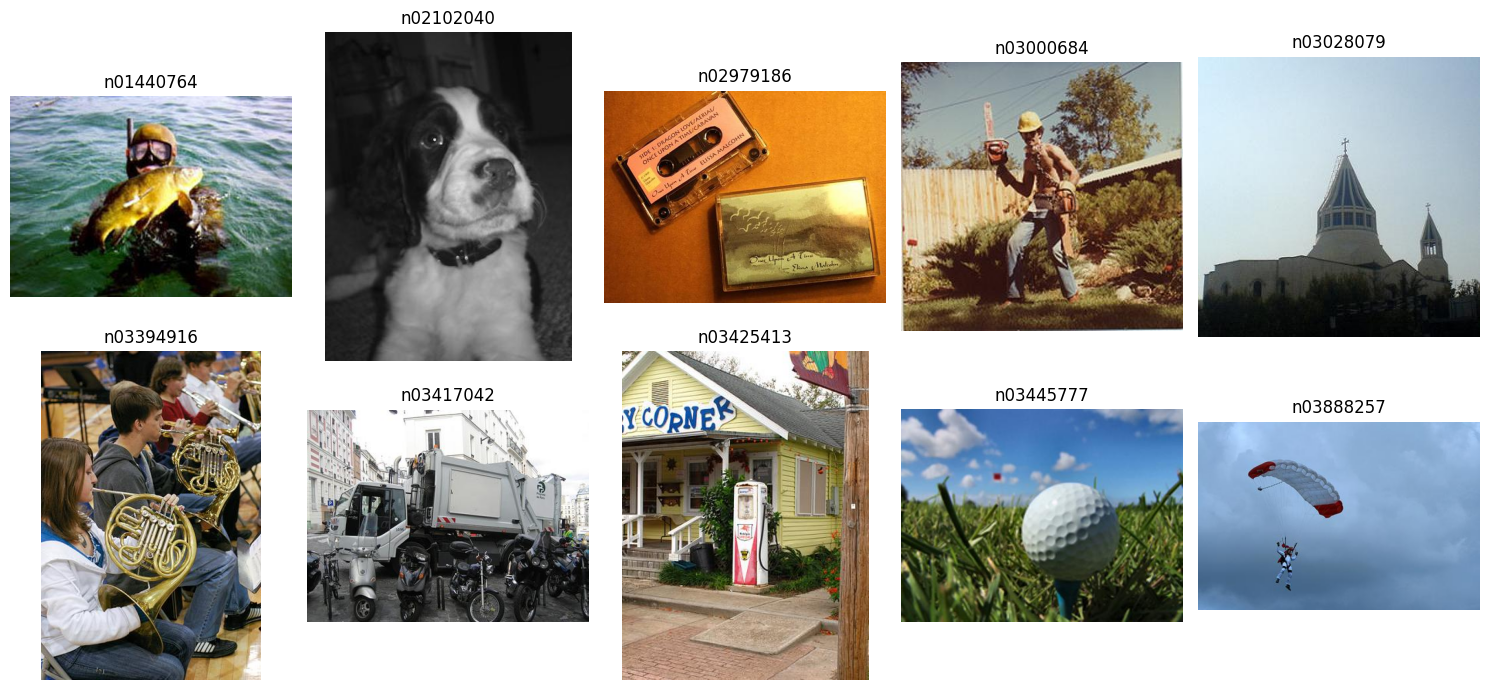

In [ ]:
import matplotlib.pyplot as plt

classes = df["true_label"].unique()

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
axes = axes.flatten()

ROOT = Path.cwd().parent

for i, label in enumerate(classes):
    row = df[df["true_label"] == label].iloc[0]

    img_path = ROOT / row["path"]
    img = Image.open(img_path).convert("RGB")

    axes[i].imshow(img)
    axes[i].set_title(label)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [38]:
ROOT = Path.cwd().parent

errors = []
resnet_shapes = set()
efficientnet_shapes = set()

for _, row in df.iterrows():

    img_path = ROOT / row["path"]

    try:
        original, resnet_image, efficientnet_image = prp.preprocess_image(img_path)

        # Comprobar dimensiones
        assert resnet_image.shape == (3, 224, 224)
        assert efficientnet_image.shape == (3, 224, 224)

        # Comprobar que los tensores contienen valores válidos
        assert torch.isfinite(resnet_image).all()
        assert torch.isfinite(efficientnet_image).all()

        resnet_shapes.add(tuple(resnet_image.shape))
        efficientnet_shapes.add(tuple(efficientnet_image.shape))

    except Exception as e:
        errors.append({
            "image_id": row["image_id"],
            "path": str(img_path),
            "error": str(e)
        })

print(f"Total de imágenes comprobadas: {len(df)}")
print(f"Errores: {len(errors)}")

if errors:
    print("\nImágenes con errores:")
    for error in errors:
        print(error)

else:
    print("Todas las imágenes se han preprocesado correctamente.")

print("\nShapes ResNet50:", resnet_shapes)
print("Shapes EfficientNet-B0:", efficientnet_shapes)

Total de imágenes comprobadas: 300
Errores: 0
Todas las imágenes se han preprocesado correctamente.

Shapes ResNet50: {(3, 224, 224)}
Shapes EfficientNet-B0: {(3, 224, 224)}


## Conclusiones del preprocesamiento

Se ha comprobado el correcto funcionamiento del preprocesamiento sobre las 300 imágenes seleccionadas del conjunto de datos. Todas las imágenes se han podido cargar y transformar sin errores.

Se han aplicado las transformaciones asociadas a los pesos preentrenados de ResNet50 y EfficientNet-B0, obteniendo en ambos casos tensores de dimensiones (3, 224, 224). Asimismo, se ha verificado que los tensores generados contienen valores numéricos válidos.

Por tanto, el pipeline de preprocesamiento se considera validado para la muestra seleccionada.